# 03 · Association rules: Apriori, Apriori-based sequential patterns, A-Close (closed itemsets)

**Transactions.** Each review is one transaction: the set of aspects it mentions plus one
sentiment item (`sent=pos | neu | neg`). Example: {room, staff, location, sent=pos}. The two
domains are mined separately, because their aspect vocabularies differ.

**Sequences.** The same aspects in the order the reviewer first mentions them, for example
⟨location → room → staff⟩. These are used for sequential patterns.

**Assumed parameters** (the question allows them to be assumed and stated):

| Task | Hotels (218,295 reviews) | Cars (40,843 reviews) | Why |
|---|---|---|---|
| Apriori: min support | 5 % (≈ 10.9k reviews) | 2 % (≈ 820 reviews) | The Pareto chart shows the 12 "vital" aspects each appear in ≥ 15–25 % of reviews, so 5 % / 2 % keep 3- to 5-aspect combinations without an explosion of itemsets |
| Apriori: min confidence | 60 % | 50 % | Car reviews are shorter, with fewer aspects each (median 4 vs 7) |
| Sentiment-targeted rules | support 1 %, any confidence, ranked by lift | same | Negative reviews are only ~8 %, so rules predicting them can never reach 60 % confidence |
| Sequential patterns (GSP): min support / confidence | 5 % / 35 % | 2 % / 20 % | Every pair's support is split between its two orders (⟨a→b⟩ vs ⟨b→a⟩), so sequential confidences run far below itemset confidences. The best single-step hotel rule, ⟨room⟩ ⇒ ⟨staff⟩, reaches only 43 % |
| A-Close: min support | 5 % | 2 %, plus a low-support demonstration at 0.1 % | |

In [1]:
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import algos as A          # from-scratch Apriori, A-Close, GSP (src/algos.py, self-tested)
import plots as P

warnings.filterwarnings("ignore", category=FutureWarning)
P.set_style()
CLEAN = Path(r"C:\data\ASBD_exam\clean")
TABLES = Path("../outputs/tables")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

df = pd.read_parquet(CLEAN / "reviews_model.parquet")
DATA = {}
for dom in ["hotel", "car"]:
    d = df[df["domain"] == dom]
    tx = [list(a) + [f"sent={s}"] for a, s in zip(d["aspects"], d["sent_class"])]
    seqs = [list(a) for a in d["aspects"]]
    DATA[dom] = dict(tx=tx, seqs=seqs, n=len(tx))
    print(f"{dom}: {len(tx):,} transactions, {len({i for t in tx for i in t})} distinct items, "
          f"mean {np.mean([len(t) for t in tx]):.2f} items per transaction")
PARAM = {"hotel": dict(sup=0.05, conf=0.60, seq_sup=0.05, seq_conf=0.35),
         "car": dict(sup=0.02, conf=0.50, seq_sup=0.02, seq_conf=0.20)}

hotel: 218,298 transactions, 25 distinct items, mean 7.87 items per transaction


car: 40,845 transactions, 22 distinct items, mean 4.79 items per transaction


### Data transformation: from review text to transaction and sequence
Three hotel reviews, and the start of the one-hot (transaction × item) matrix that Apriori
implementations such as mlxtend expect.

In [2]:
from mlxtend.preprocessing import TransactionEncoder

h = df[df["domain"] == "hotel"].head(3)
for (_, r), t in zip(h.iterrows(), DATA["hotel"]["tx"][:3]):
    print(f"TEXT: {r['text'][:150]}...\n  sequence   : {' -> '.join(r['aspects'])}\n  transaction: {sorted(t)}\n")
te = TransactionEncoder()
onehot = {dom: pd.DataFrame(te.fit(DATA[dom]["tx"]).transform(DATA[dom]["tx"]), columns=te.columns_) for dom in DATA}
onehot["hotel"].iloc[:3, :12]

TEXT: we stayed in a 3 bedroomed-suite which was well furnished and the staff perfect hosts. they even organised a birthday cake for my Mum (we were all the...
  sequence   : staff -> room -> location -> food
  transaction: ['food', 'location', 'room', 'sent=pos', 'staff']

TEXT: We stayed at the Ascott Beijing this summer for 1 week in a family of 5. It is centrally located. When you are a european with kids staying for a few ...
  sequence   : location -> size -> service -> transport
  transaction: ['location', 'sent=pos', 'service', 'size', 'transport']

TEXT: check-in:my friends are i arrived from different countries @ different times and were greeted in the same lousy way. the bellboy did not help with lug...
  sequence   : checkin -> staff -> lobby -> room -> size -> bathroom -> location -> food -> transport -> breakfast -> gym_spa
  transaction: ['bathroom', 'breakfast', 'checkin', 'food', 'gym_spa', 'lobby', 'location', 'room', 'sent=neu', 'size', 'staff', 'transport']



,bar,bathroom,bed,breakfast,checkin,cleanliness,elevator,food,gym_spa,internet,lobby,location
0,False,False,False,False,False,False,False,True,False,False,False,True
1,False,False,False,False,False,False,False,False,False,False,False,True
2,False,True,False,True,True,False,False,True,True,False,True,True


## Part A · Apriori: frequent itemsets and association rules
`algos.apriori_bitset` is a from-scratch Apriori: level-wise **join** (shared k−1 prefix),
**prune** (every k-subset must be frequent) and **count**. Counting intersects TID-bitsets
(the vertical TID-list layout), so the database is never rescanned. The result is cross-checked
against mlxtend's FP-growth, which must find exactly the same number of itemsets.

In [3]:
from mlxtend.frequent_patterns import fpgrowth

FREQ = {}
for dom in DATA:
    p, n = PARAM[dom], DATA[dom]["n"]
    t0 = time.time()
    F = A.apriori_bitset(DATA[dom]["tx"], p["sup"])
    t_ap = time.time() - t0
    t0 = time.time()
    fi_mx = fpgrowth(onehot[dom], min_support=p["sup"], use_colnames=True)
    t_fp = time.time() - t0
    FREQ[dom] = F
    levels = Counter(len(s) for s in F)
    print(f"{dom} (min_sup {p['sup']:.0%} = {int(np.ceil(p['sup'] * n)):,} reviews): {len(F):,} frequent itemsets "
          f"in {t_ap:.1f}s | mlxtend FP-growth: {len(fi_mx):,} in {t_fp:.1f}s | identical: {len(F) == len(fi_mx)}")
    print("   itemsets per level L1..Lk:", dict(sorted(levels.items())))

hotel (min_sup 5% = 10,915 reviews): 2,300 frequent itemsets in 0.6s | mlxtend FP-growth: 2,300 in 2.9s | identical: True
   itemsets per level L1..Lk: {1: 25, 2: 174, 3: 501, 4: 750, 5: 587, 6: 230, 7: 33}


car (min_sup 2% = 817 reviews): 588 frequent itemsets in 0.1s | mlxtend FP-growth: 588 in 0.3s | identical: True
   itemsets per level L1..Lk: {1: 21, 2: 136, 3: 276, 4: 150, 5: 5}


In [4]:
RULES = {}
for dom in DATA:
    p, n = PARAM[dom], DATA[dom]["n"]
    RULES[dom] = A.rules_from_freq(FREQ[dom], n, min_conf=p["conf"])
    r = RULES[dom]
    print(f"{dom}: {len(r):,} strong rules (min_conf {p['conf']:.0%}); "
          f"lift > 1.2: {(r['lift'] > 1.2).sum():,}; median lift {r['lift'].median():.3f}")
print("\nHOTELS: top 12 rules by lift")
RULES["hotel"].head(12).round(3)

hotel: 8,631 strong rules (min_conf 60%); lift > 1.2: 4,157; median lift 1.193
car: 491 strong rules (min_conf 50%); lift > 1.2: 143; median lift 1.110

HOTELS: top 12 rules by lift


,antecedent,consequent,support,confidence,lift,conviction,size
0,"{bed, food, size}","{bathroom, room, sent=pos}",0.062,0.658,2.024,1.975,6
1,"{bed, cleanliness, location, size}","{bathroom, room, sent=pos}",0.053,0.658,2.022,1.971,7
2,"{bed, location, price, size}","{bathroom, room, sent=pos}",0.060,0.655,2.015,1.958,7
3,"{bed, food, room, size}","{bathroom, sent=pos}",0.062,0.667,1.982,1.991,6
4,"{bed, cleanliness, location, room, size}","{bathroom, sent=pos}",0.053,0.665,1.978,1.983,7
5,"{bed, price, size, staff}","{bathroom, room, sent=pos}",0.059,0.643,1.977,1.892,7
6,"{bed, food, size}","{bathroom, sent=pos}",0.062,0.664,1.975,1.977,5
7,"{bed, cleanliness, location, size}","{bathroom, sent=pos}",0.053,0.664,1.973,1.974,6
8,"{bed, location, size, staff}","{bathroom, room, sent=pos}",0.068,0.642,1.972,1.882,7
9,"{bed, location, price, room, size}","{bathroom, sent=pos}",0.060,0.663,1.970,1.968,7


In [5]:
print("CARS: top 12 rules by lift")
RULES["car"].head(12).round(3)

CARS: top 12 rules by lift


,antecedent,consequent,support,confidence,lift,conviction,size
0,"{comfort, electronics}",{seats},0.021,0.510,2.354,1.597,3
1,{sent=neg},{reliability},0.045,0.560,2.160,1.682,2
2,"{seats, styling}",{interior},0.033,0.537,2.143,1.619,3
3,"{seats, sent=pos, styling}",{interior},0.029,0.530,2.117,1.596,4
4,"{comfort, noise}","{ride, sent=pos}",0.025,0.513,2.105,1.553,4
5,"{cargo_space, styling}",{interior},0.026,0.525,2.096,1.579,3
6,"{comfort, noise, sent=pos}",{ride},0.025,0.563,2.096,1.673,4
7,"{cargo_space, sent=pos, styling}",{interior},0.024,0.523,2.087,1.571,4
8,"{handling, noise, sent=pos}",{ride},0.021,0.550,2.048,1.626,4
9,"{electronics, sent=pos, styling}",{interior},0.021,0.509,2.031,1.527,4


**Compact view.** The top of a lift-sorted list is crowded with near-copies of one pattern
(each with an extra item on either side). Short rules (at most 2 antecedent items, 1
consequent item) are easier to read and act on.

In [6]:
for dom in DATA:
    r = RULES[dom]
    short = r[(r["antecedent"].str.count(",") <= 1) & (r["consequent"].str.count(",") == 0)]
    print(f"{dom.upper()}: top short rules by lift")
    print(short.head(10)[["antecedent", "consequent", "support", "confidence", "lift", "conviction"]].round(3)
          .to_string(index=False), "\n")

HOTEL: top short rules by lift


         antecedent consequent  support  confidence  lift  conviction
     {bar, service}     {food}    0.054       0.685 1.816       1.977
{bathroom, checkin}      {bed}    0.055       0.617 1.728       1.678
   {bar, breakfast}     {food}    0.062       0.651 1.727       1.787
        {bed, size} {bathroom}    0.145       0.694 1.702       1.936
     {bed, checkin} {bathroom}    0.055       0.693 1.701       1.931
       {bar, price}     {food}    0.080       0.640 1.698       1.732
   {bathroom, view}      {bed}    0.051       0.602 1.687       1.617
         {bar, bed} {bathroom}    0.062       0.686 1.682       1.885
        {bar, size}     {food}    0.071       0.624 1.655       1.658
    {bar, bathroom}     {food}    0.065       0.622 1.650       1.648 

CAR: top short rules by lift
            antecedent    consequent  support  confidence  lift  conviction
{comfort, electronics}       {seats}    0.021       0.510 2.354       1.597
            {sent=neg} {reliability}    0.045 

**Inferences (Apriori)**
* The from-scratch Apriori and mlxtend's FP-growth find **exactly the same itemsets** (2,300 for
  hotels at 5 %, 588 for cars at 2 %), which confirms the implementation. Hotel itemsets reach
  7 items, because hotel reviews mention ~7 aspects each; car itemsets stop at 5.
* The strongest hotel rules form one family: **{bed, size, …} ⇒ {bathroom}**, lift ≈ 2.
  Reviewers who describe the bed and the room size almost always go on to describe the bathroom.
  This is a "room inspection" reviewing style.
* In cars, **{comfort, electronics} ⇒ {seats}** (lift 2.35), **{seats, styling} ⇒ {interior}**
  and **{comfort, noise} ⇒ {ride}** show which aspects are judged together: cabin features
  group with the interior, noise with ride quality.
* The most actionable car rule is **{sent=neg} ⇒ {reliability}** (confidence 56 %, lift 2.16).
  More than half of all negative car reviews discuss reliability.

### Rules that predict a negative review
Negative reviews are only ~8 %, so a rule ending in `sent=neg` can never reach 60 % confidence.
Here the consequent is fixed to {sent=neg} and the rules are ranked by **lift**: how many times
more likely a review is to be negative when it mentions that aspect combination.

In [7]:
NEG, POS = {}, {}
for dom in DATA:
    n = DATA[dom]["n"]
    F1 = A.apriori_bitset(DATA[dom]["tx"], 0.01)
    NEG[dom] = A.rules_from_freq(F1, n, min_conf=0.0, consequent="sent=neg")
    POS[dom] = A.rules_from_freq(F1, n, min_conf=0.0, consequent="sent=pos")
    base = sum("sent=neg" in t for t in DATA[dom]["tx"]) / n
    print(f"{dom}: P(sent=neg) = {base:.3f}; {len(NEG[dom])} rules with support >= 1% ending in sent=neg")
    print(NEG[dom].head(8)[["antecedent", "support", "confidence", "lift"]].round(3).to_string(index=False), "\n")
    print(f"{dom}: aspect sets with the HIGHEST lift towards sent=pos")
    print(POS[dom].head(5)[["antecedent", "support", "confidence", "lift"]].round(3).to_string(index=False), "\n")

hotel: P(sent=neg) = 0.077; 63 rules with support >= 1% ending in sent=neg
                   antecedent  support  confidence  lift
                   {bathroom}    0.033       0.081 1.048
             {bathroom, room}    0.031       0.078 1.007
                       {room}    0.066       0.074 0.960
      {bathroom, cleanliness}    0.016       0.074 0.960
                        {bed}    0.026       0.072 0.934
            {bathroom, staff}    0.020       0.072 0.928
{bathroom, cleanliness, room}    0.015       0.071 0.923
                    {checkin}    0.012       0.071 0.922 

hotel: aspect sets with the HIGHEST lift towards sent=pos
                            antecedent  support  confidence  lift
               {bar, food, pool, view}    0.010       0.967 1.149
         {breakfast, food, pool, view}    0.010       0.967 1.149
         {bar, food, pool, room, view}    0.010       0.967 1.149
   {breakfast, food, pool, room, view}    0.010       0.967 1.149
{bar, bathroom, breakf

**Inferences (sentiment-targeted rules)**
* **Cars:** {dealer, reliability} ⇒ negative has **lift 4.2**. A review that mentions both the
  dealer and reliability is four times as likely as average to be negative (33 % vs 8 %). Dealer
  alone gives lift 2.8 and reliability alone 2.2. Bad car reviews are about breakdowns and how
  the dealer handled them.
* **Hotels:** no aspect combination with ≥ 1 % support raises the chance of a negative review
  by more than 5 % (best lift ≈ 1.05, for bathroom). Negative hotel reviews mention the *same*
  aspects as positive ones; the difference is in *what* is said about them, not *which*
  aspects are mentioned.
* Positive sentiment is most strongly associated with **leisure facilities** (pool, view, bar,
  food: confidence ≈ 97 %) for hotels, and with **comfort + ride + fuel economy** for cars.

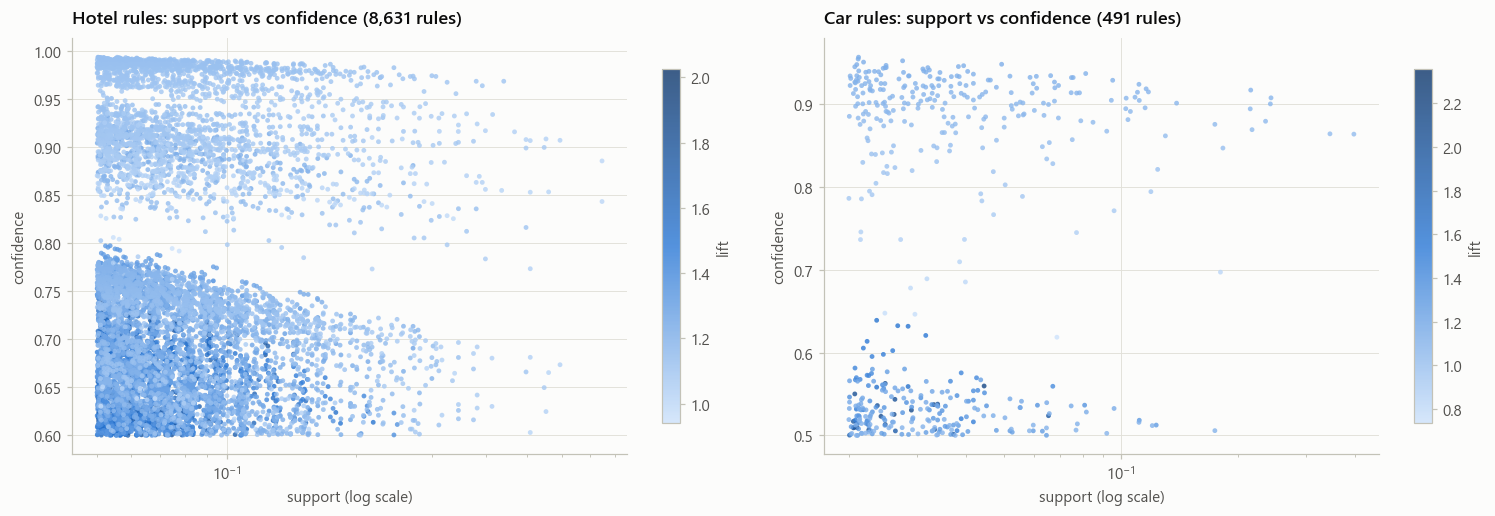

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, dom in zip(axs, ["hotel", "car"]):
    r = RULES[dom]
    sc = ax.scatter(r["support"], r["confidence"], c=r["lift"], cmap=P.SEQUENTIAL, s=10, alpha=0.8,
                    edgecolor="none", rasterized=True)
    fig.colorbar(sc, ax=ax, label="lift", shrink=0.85)
    ax.set_xscale("log")
    ax.set_xlabel("support (log scale)")
    ax.set_ylabel("confidence")
    ax.set_title(f"{dom.title()} rules: support vs confidence ({len(r):,} rules)")
fig.tight_layout()
P.save(fig, "a01_rules_scatter")
plt.show()

## Part B · Apriori-based sequential patterns (GSP / AprioriAll style)
A sequence pattern ⟨a → b → c⟩ is supported by a review that mentions a, then later b, then
later c (gaps allowed). `algos.gsp` mines these level-wise, like Apriori:
* **join:** s1 with s2 when s1 minus its first item equals s2 minus its last item;
* **prune:** every sub-sequence with one item removed must be frequent;
* **count:** vectorised over a position matrix.

Sequential rules read **⟨prefix⟩ ⇒ ⟨continuation⟩**: "a review that first mentions the prefix
in this order goes on to mention the continuation". Confidence = sup(sequence) / sup(prefix).

In [9]:
SEQ, SEQR = {}, {}
for dom in DATA:
    p, n, seqs = PARAM[dom], DATA[dom]["n"], DATA[dom]["seqs"]
    first = pd.Series([s[0] for s in seqs if s]).value_counts(normalize=True).head(6).round(3)
    print(f"{dom}: aspect mentioned FIRST:", first.to_dict())
    t0 = time.time()
    SEQ[dom] = A.gsp(seqs, p["seq_sup"])
    SEQR[dom] = A.sequential_rules(SEQ[dom], n, min_conf=p["seq_conf"])
    by_len = Counter(len(s) for s in SEQ[dom])
    print(f"   {len(SEQ[dom])} frequent sequences (min_sup {p['seq_sup']:.0%}) in {time.time() - t0:.1f}s, by length: "
          f"{dict(sorted(by_len.items()))}; {len(SEQR[dom])} sequential rules (min_conf {p['seq_conf']:.0%})")
top_seq = {dom: pd.DataFrame([(" -> ".join(s), c / DATA[dom]["n"]) for s, c in SEQ[dom].items() if len(s) >= 2],
                             columns=["sequence", "support"]).sort_values("support", ascending=False) for dom in DATA}
print("\nmost frequent hotel sequences (length >= 2):")
print(top_seq["hotel"].head(10).round(3).to_string(index=False))
print("\nmost frequent car sequences (length >= 2):")
print(top_seq["car"].head(8).round(3).to_string(index=False))

hotel: aspect mentioned FIRST: {'room': 0.298, 'location': 0.202, 'staff': 0.112, 'price': 0.109, 'cleanliness': 0.044, 'service': 0.036}


   274 frequent sequences (min_sup 5%) in 8.6s, by length: {1: 22, 2: 152, 3: 100}; 35 sequential rules (min_conf 35%)
car: aspect mentioned FIRST: {'fuel_economy': 0.161, 'engine': 0.128, 'styling': 0.088, 'price': 0.087, 'reliability': 0.084, 'ride': 0.081}


   175 frequent sequences (min_sup 2%) in 0.6s, by length: {1: 18, 2: 157}; 21 sequential rules (min_conf 20%)

most frequent hotel sequences (length >= 2):
           sequence  support
      room -> staff    0.383
       room -> size    0.372
   room -> bathroom    0.366
room -> cleanliness    0.339
      room -> price    0.321
   room -> location    0.314
        room -> bed    0.307
  room -> breakfast    0.294
       room -> food    0.278
   location -> room    0.238

most frequent car sequences (length >= 2):
                   sequence  support
     engine -> fuel_economy    0.113
     fuel_economy -> engine    0.086
       ride -> fuel_economy    0.073
      fuel_economy -> price    0.072
         engine -> handling    0.070
         engine -> interior    0.069
fuel_economy -> reliability    0.066
             ride -> engine    0.065


In [10]:
print("HOTELS: sequential rules, top 12 by confidence")
SEQR["hotel"].sort_values("confidence", ascending=False).head(12).round(3)

HOTELS: sequential rules, top 12 by confidence


,antecedent,consequent,length,support,confidence,lift
7,location -> room,size,3,0.103,0.434,0.954
20,room,staff,2,0.383,0.433,0.660
0,price -> room,bathroom,3,0.063,0.432,1.061
33,checkin,room,2,0.073,0.430,0.487
9,price -> room,size,3,0.062,0.427,0.938
11,room,size,2,0.372,0.421,0.926
1,room,bathroom,2,0.366,0.414,1.016
2,room -> bed,bathroom,3,0.124,0.404,0.992
4,location -> room,bathroom,3,0.096,0.404,0.991
5,bed,bathroom,2,0.144,0.403,0.989


In [11]:
print("CARS: sequential rules, top 10 by lift")
SEQR["car"].head(10).round(3)

CARS: sequential rules, top 10 by lift


,antecedent,consequent,length,support,confidence,lift
0,interior,seats,2,0.060,0.238,1.101
1,seats,comfort,2,0.048,0.221,0.939
2,dealer,reliability,2,0.024,0.216,0.833
3,interior,styling,2,0.052,0.207,0.769
4,engine,fuel_economy,2,0.113,0.283,0.614
5,ride,engine,2,0.065,0.241,0.604
6,ride,fuel_economy,2,0.073,0.272,0.589
7,comfort,fuel_economy,2,0.063,0.266,0.578
8,handling,fuel_economy,2,0.063,0.261,0.567
9,styling,engine,2,0.060,0.222,0.554


### Order matters: the same pair of aspects in both directions
A plain itemset rule cannot tell ⟨a → b⟩ from ⟨b → a⟩. Sequences can. Below, the support of
each order for the most common hotel pairs.

In [12]:
pairs = [(a, b) for (a, b) in [s for s in SEQ["hotel"] if len(s) == 2] if a < b]
order = pd.DataFrame([(a, b, SEQ["hotel"].get((a, b), 0) / DATA["hotel"]["n"],
                       SEQ["hotel"].get((b, a), 0) / DATA["hotel"]["n"]) for a, b in pairs],
                     columns=["a", "b", "sup <a,b>", "sup <b,a>"])
order["ratio a-first"] = order["sup <a,b>"] / (order["sup <a,b>"] + order["sup <b,a>"])
order.sort_values("sup <a,b>", ascending=False).head(10).round(3)

,a,b,"sup <a,b>","sup <b,a>",ratio a-first
29,room,staff,0.383,0.212,0.644
37,room,size,0.372,0.068,0.846
52,location,room,0.238,0.314,0.432
35,location,staff,0.224,0.190,0.541
19,room,service,0.194,0.062,0.757
60,location,price,0.191,0.144,0.570
31,cleanliness,staff,0.174,0.133,0.567
14,size,staff,0.173,0.142,0.549
50,location,size,0.155,0.153,0.503
43,cleanliness,location,0.154,0.144,0.517


**Inferences (sequential patterns)**
* Reviews follow a **narrative order**. Hotel reviews most often open with the *room* (30 %),
  then *location* (20 %), *staff* (11 %) or *price* (11 %). Car reviews open with *fuel
  economy* (16 %) or the *engine* (13 %).
* The most frequent hotel sequence is ⟨room → staff⟩ (38 % of reviews). *Size* comes after
  *room* in **85 %** of the reviews that mention both: size is described as a property of the
  room. *Location* and *room* are the exception, with room first 57 % of the time.
* Three-step rules describe the typical walk-through:
  **⟨location → room⟩ ⇒ ⟨size⟩** (confidence 43 %) and **⟨price → room⟩ ⇒ ⟨bathroom⟩**
  (43 %, lift 1.06). Reviewers who start with the deal or the location go on to judge the room
  in detail.
* In cars, ⟨engine → fuel economy⟩ (11.3 %) is more common than the reverse (8.6 %):
  performance is discussed before economy. **⟨dealer⟩ ⇒ ⟨reliability⟩** (22 %) is the
  complaint narrative already seen in the itemset rules: the dealer visit comes first, then the
  reliability problem.
* The lift of a sequential rule compares with the consequent's frequency *anywhere* in a
  review. Values below 1 are therefore expected whenever the consequent often comes *before*
  the antecedent, so confidence is the better ranking here.

## Part C · A-Close: closed frequent itemsets (CFIs) and closed association rules
A-Close mines **minimal generators** level-wise and closes each one with the Galois
closure f(g) = i(t(g)), the items shared by every transaction that contains g. The resulting
CFIs are a **lossless** summary of all frequent itemsets: the support of any frequent itemset
is the largest support among its closed supersets. Rules are then generated from the CFIs (the
generic min-max basis): **exact rules** g ⇒ f(g)∖g with 100 % confidence, and **approximate
rules** g ⇒ C∖g for closed supersets C.

In [13]:
CL = {}
for dom in DATA:
    p, n = PARAM[dom], DATA[dom]["n"]
    t0 = time.time()
    cfis, table, gens = A.aclose(DATA[dom]["tx"], p["sup"])
    t_ac = time.time() - t0
    closed_ref, maximal = A.fi_closed_maximal(FREQ[dom])
    CL[dom] = dict(cfis=cfis, table=table, gens=gens, mfi=maximal)
    nontrivial = sum(g != c for g, c, _ in gens)
    print(f"{dom} (min_sup {p['sup']:.0%}): A-Close found {len(cfis):,} CFIs from {len(gens):,} minimal generators in {t_ac:.1f}s; "
          f"non-trivial closures: {nontrivial}; equals closed(Apriori FIs): {set(cfis) == set(closed_ref)}")
    print(f"   FI = {len(FREQ[dom]):,}   CFI = {len(cfis):,}   MFI = {len(maximal):,}")
    some = list(FREQ[dom])[::max(1, len(FREQ[dom]) // 200)]
    assert all(A.support_from_cfis(s, cfis) == FREQ[dom][s] for s in some)   # lossless property
print("lossless check passed: supports of sampled frequent itemsets recovered from the CFIs alone")
CL["hotel"]["table"].head(10)

hotel (min_sup 5%): A-Close found 2,300 CFIs from 2,300 minimal generators in 1.4s; non-trivial closures: 0; equals closed(Apriori FIs): True
   FI = 2,300   CFI = 2,300   MFI = 356
car (min_sup 2%): A-Close found 588 CFIs from 588 minimal generators in 0.1s; non-trivial closures: 0; equals closed(Apriori FIs): True
   FI = 588   CFI = 588   MFI = 213
lossless check passed: supports of sampled frequent itemsets recovered from the CFIs alone


,minimal_generator,closure (CFI),support_count,support
0,{room},{room},192932,0.883801
1,{sent=pos},{sent=pos},183738,0.841684
2,"{room, sent=pos}","{room, sent=pos}",162660,0.745128
3,{staff},{staff},143290,0.656396
4,{location},{location},132728,0.608013
5,"{room, staff}","{room, staff}",129926,0.595177
6,"{sent=pos, staff}","{sent=pos, staff}",122236,0.559950
7,"{location, room}","{location, room}",120536,0.552163
8,"{location, sent=pos}","{location, sent=pos}",119365,0.546798
9,{price},{price},111261,0.509675


In [14]:
CR = {}
for dom in DATA:
    CR[dom] = A.closed_rules(DATA[dom]["n"], CL[dom]["cfis"], CL[dom]["gens"], min_conf=PARAM[dom]["conf"])
    print(f"{dom}: {len(CR[dom]):,} closed rules ({(CR[dom]['type'] == 'exact').sum()} exact, "
          f"{(CR[dom]['type'] == 'approximate').sum():,} approximate) vs {len(RULES[dom]):,} Apriori rules")
print("\nHOTELS: closed (min-max) rules, top 10 by lift")
CR["hotel"].head(10).round(3)

hotel: 8,631 closed rules (0 exact, 8,631 approximate) vs 8,631 Apriori rules
car: 491 closed rules (0 exact, 491 approximate) vs 491 Apriori rules

HOTELS: closed (min-max) rules, top 10 by lift


,antecedent,consequent,support,confidence,lift,type
0,"{bed, food, size}","{bathroom, room, sent=pos}",0.062,0.658,2.024,approximate
1,"{bed, cleanliness, location, size}","{bathroom, room, sent=pos}",0.053,0.658,2.022,approximate
2,"{bed, location, price, size}","{bathroom, room, sent=pos}",0.060,0.655,2.015,approximate
3,"{bed, food, room, size}","{bathroom, sent=pos}",0.062,0.667,1.982,approximate
4,"{bed, cleanliness, location, room, size}","{bathroom, sent=pos}",0.053,0.665,1.978,approximate
5,"{bed, price, size, staff}","{bathroom, room, sent=pos}",0.059,0.643,1.977,approximate
6,"{bed, food, size}","{bathroom, sent=pos}",0.062,0.664,1.975,approximate
7,"{bed, cleanliness, location, size}","{bathroom, sent=pos}",0.053,0.664,1.973,approximate
8,"{bed, location, size, staff}","{bathroom, room, sent=pos}",0.068,0.642,1.972,approximate
9,"{bed, location, price, room, size}","{bathroom, sent=pos}",0.060,0.663,1.970,approximate


### Why CFI = FI here, and where closure starts to matter
With 218k reviews, two different itemsets almost never have *exactly* the same support: no
aspect is always mentioned together with another. So every frequent itemset is its own closure
and the CFI summary is lossless but no smaller. Exact co-occurrences only appear when the
support threshold is very low (a few dozen reviews). The run below repeats A-Close on the car
reviews at **min_sup = 0.1 % (≈ 41 reviews)**.

In [15]:
t0 = time.time()
cf_lo, tab_lo, gens_lo = A.aclose(DATA["car"]["tx"], 0.001)
F_lo = A.apriori_bitset(DATA["car"]["tx"], 0.001)
closed_lo, max_lo = A.fi_closed_maximal(F_lo)
print(f"cars at 0.1%: FI = {len(F_lo):,}  CFI = {len(cf_lo):,}  MFI = {len(max_lo):,}  "
      f"(A-Close == closed(Apriori): {set(cf_lo) == set(closed_lo)}; {time.time() - t0:.1f}s)")
nt = tab_lo[tab_lo["minimal_generator"] != tab_lo["closure (CFI)"]]
print(f"{len(nt)} generators whose closure is larger than the generator, e.g.:")
print(nt.sort_values("support_count", ascending=False).head(8).to_string(index=False))
exact_lo = A.closed_rules(DATA["car"]["n"], cf_lo, gens_lo, min_conf=1.0)
added = Counter(c for c in exact_lo["consequent"])
print(f"\n{len(exact_lo)} exact rules (confidence 100%); consequents: {dict(added)}")

cars at 0.1%: FI = 13,429  CFI = 13,334  MFI = 3,261  (A-Close == closed(Apriori): True; 1.3s)
95 generators whose closure is larger than the generator, e.g.:
                                           minimal_generator                                                          closure (CFI)  support_count  support
           {cargo_space, comfort, fuel_economy, noise, ride}            {cargo_space, comfort, fuel_economy, noise, ride, sent=pos}            134 0.003281
           {cargo_space, comfort, ride, seats, transmission}            {cargo_space, comfort, ride, seats, sent=pos, transmission}             90 0.002203
     {cargo_space, comfort, engine, interior, ride, styling}      {cargo_space, comfort, engine, interior, ride, sent=pos, styling}             86 0.002106
{cargo_space, comfort, engine, fuel_economy, handling, ride} {cargo_space, comfort, engine, fuel_economy, handling, ride, sent=pos}             80 0.001959
        {cargo_space, comfort, fuel_economy, noise, styling} 


95 exact rules (confidence 100%); consequents: {'{sent=pos}': 95}


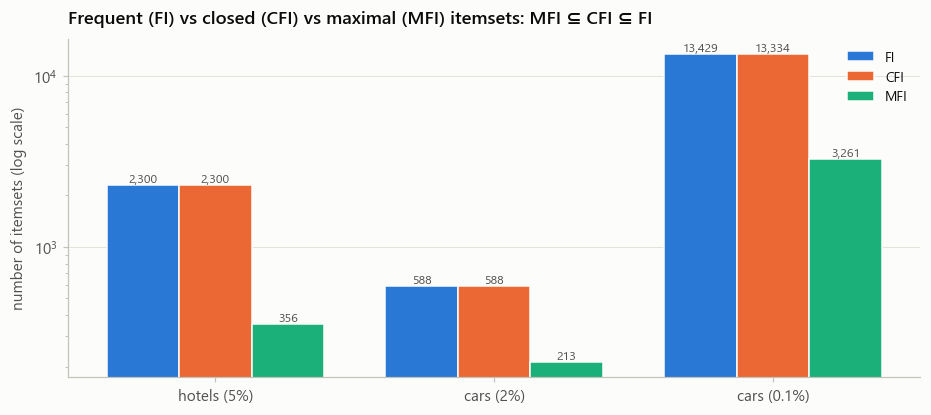

,hotels (5%),cars (2%),cars (0.1%)
FI,2300,588,13429
CFI,2300,588,13334
MFI,356,213,3261


In [16]:
counts = pd.DataFrame({"hotels (5%)": [len(FREQ['hotel']), len(CL['hotel']['cfis']), len(CL['hotel']['mfi'])],
                       "cars (2%)": [len(FREQ['car']), len(CL['car']['cfis']), len(CL['car']['mfi'])],
                       "cars (0.1%)": [len(F_lo), len(cf_lo), len(max_lo)]}, index=["FI", "CFI", "MFI"])
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(counts.columns))
for i, (name, row) in enumerate(counts.iterrows()):
    ax.bar(x + (i - 1) * 0.26, row.values, 0.26, color=P.SERIES[i], label=name, edgecolor=P.SURFACE, linewidth=1)
    for xi, v in zip(x, row.values):
        ax.text(xi + (i - 1) * 0.26, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=P.INK2)
ax.set_xticks(x)
ax.set_xticklabels(counts.columns)
ax.set_yscale("log")
ax.set_ylabel("number of itemsets (log scale)")
ax.set_title("Frequent (FI) vs closed (CFI) vs maximal (MFI) itemsets: MFI ⊆ CFI ⊆ FI")
ax.legend()
ax.grid(axis="x", visible=False)
P.save(fig, "a02_fi_cfi_mfi")
plt.show()
counts

**Inferences (A-Close)**
* A-Close's CFIs equal the closed itemsets derived from Apriori's output in every run. The
  **lossless property** was verified too: the support of every sampled frequent itemset is
  recovered from the CFIs alone.
* At the working supports (5 % / 2 %), **every frequent itemset is closed** (FI = CFI), so
  every generator is its own closure and there are no exact (100 %) rules. On a large dataset,
  two aspect combinations practically never occur in exactly the same reviews. The useful
  compression comes from the **maximal** itemsets instead (2,300 → 356 for hotels, 6.5×), which
  is lossy: the supports are lost.
* At a low support (0.1 %, about 41 car reviews), closure starts to matter: **95 itemsets are
  absorbed into larger closed sets**, and every one of them gains the item *sent=pos*. These
  give 95 **exact rules** such as {cargo space, comfort, fuel economy, noise, ride} ⇒ {sent=pos}
  (134 reviews, all positive): combinations of comfort-related praise that never once appear
  in a non-positive car review.

## Save the rule tables

In [17]:
for dom in DATA:
    RULES[dom].to_csv(TABLES / f"apriori_rules_{dom}.csv", index=False)
    SEQR[dom].to_csv(TABLES / f"sequential_rules_{dom}.csv", index=False)
    CR[dom].to_csv(TABLES / f"closed_rules_{dom}.csv", index=False)
    CL[dom]["table"].to_csv(TABLES / f"aclose_generators_{dom}.csv", index=False)
    NEG[dom].to_csv(TABLES / f"neg_rules_{dom}.csv", index=False)
print("saved:", sorted(p.name for p in TABLES.glob("*rules*.csv")))

saved: ['apriori_rules_car.csv', 'apriori_rules_hotel.csv', 'closed_rules_car.csv', 'closed_rules_hotel.csv', 'neg_rules_car.csv', 'neg_rules_hotel.csv', 'sequential_rules_car.csv', 'sequential_rules_hotel.csv']
